In [1]:
import numpy as np

embeddings = np.load("human_demo_embeddings_2.npy")

In [5]:

embeddings["original_frame"]

(262, 720, 1280, 3)

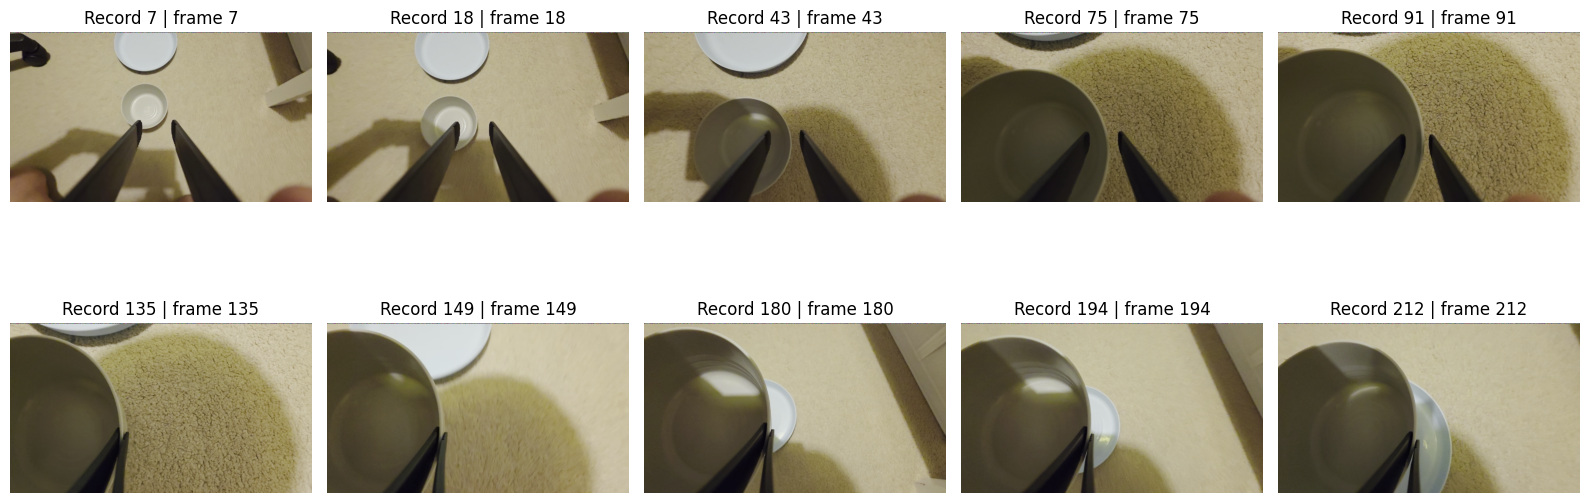

In [8]:
import matplotlib.pyplot as plt

frames = embeddings["original_frame"]
if len(frames) < 10:
    raise ValueError(f"Need at least 10 frames, found {len(frames)}.")

rng = np.random.default_rng(1729)
sampled_indices = np.sort(rng.choice(len(frames), size=10, replace=False))
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for axis, index in zip(axes.flat, sampled_indices):
    axis.imshow(frames[index])
    frame_number = embeddings["frame_number"][index]
    axis.set_title(f"Record {index} | frame {frame_number}")
    axis.axis("off")
fig.tight_layout()
plt.show()

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Created put the bowl on the plate
{'agentview': (224, 224, 3), 'wrist': (224, 224, 3), 'proprio': (9,)}


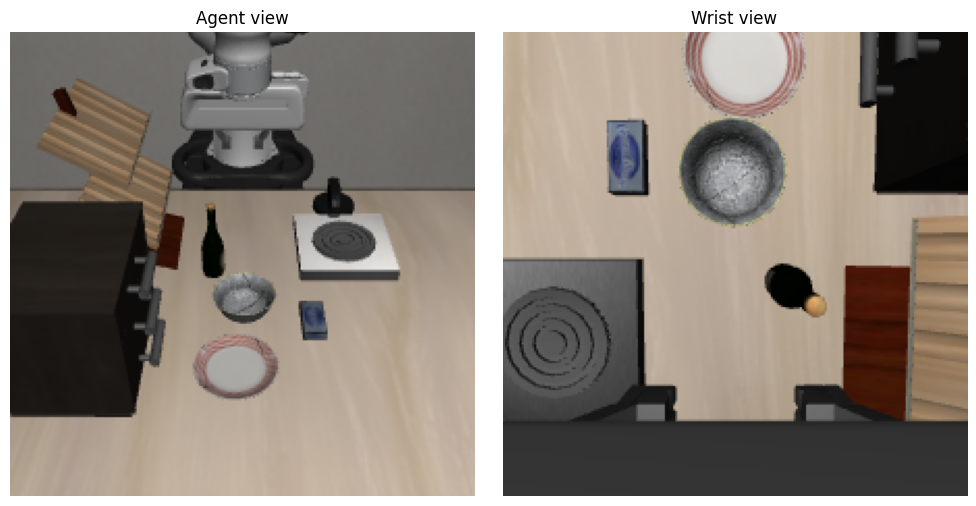

In [39]:
from train import LiberoEnv

libero_env = LiberoEnv(suite="libero_goal", task_id=8, seed=123)
libero_observation, libero_info = libero_env.reset()
print(f"Created {libero_env.task_description}")
print({key: value.shape for key, value in libero_observation.items()})

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(libero_observation["agentview"])
axes[0].set_title("Agent view")
axes[1].imshow(libero_observation["wrist"])
axes[1].set_title("Wrist view")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
plt.show()

In [41]:
libero_observation["proprio"]


array([-2.0846467e-01, -4.2471713e-14,  1.1732795e+00,  9.9959660e-01,
        2.4621282e-04, -2.8400121e-02, -6.9952957e-06,  2.0674653e-02,
       -2.0674642e-02], dtype=float32)

(9,) [-2.3808366e-01 -3.0900436e-03  9.0999579e-01  9.7823876e-01
  3.8129089e-03  2.0744707e-01 -3.2724938e-04  2.0973714e-02
 -1.9346779e-02]
After close: [-2.3816419e-01 -3.2383515e-03  9.0999776e-01  9.7825384e-01
  2.9161649e-03  2.0739058e-01 -2.4634015e-04  2.0826640e-02
 -1.9492261e-02]


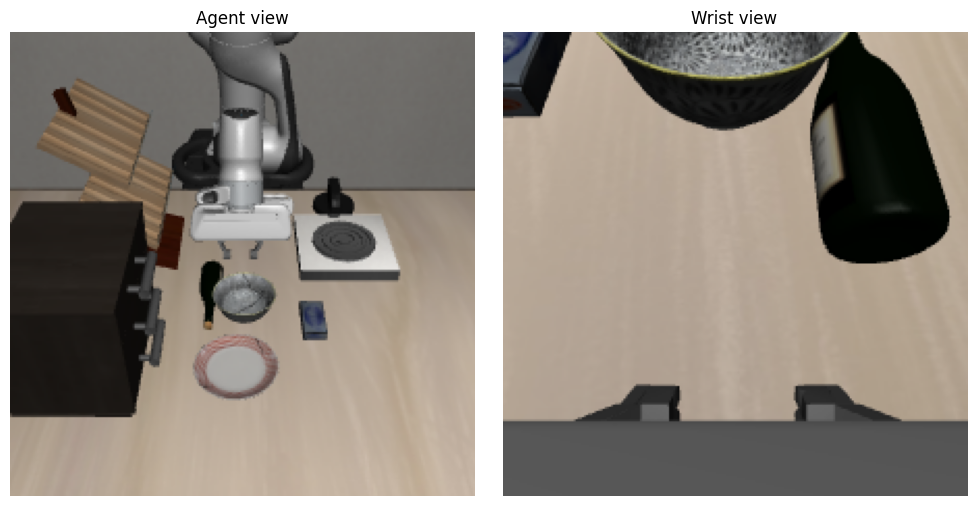

In [46]:
import numpy as np
import matplotlib.pyplot as plt
proprio = np.asarray(libero_observation["proprio"])
print(proprio.shape, proprio)

# Close the gripper for a few steps and compare
close_action = np.zeros(4, dtype=np.float32)
close_action[2] = -1.0
for _ in range(20):
    libero_observation, *_ = libero_env.step(close_action)
print("After close:", np.asarray(libero_observation["proprio"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(libero_observation["agentview"])
axes[0].set_title("Agent view")
axes[1].imshow(libero_observation["wrist"])
axes[1].set_title("Wrist view")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
plt.show()